In [ ]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
    
from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC106.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [14]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [15]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.


2026-05-25 02:58:44.550435: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-05-25 02:58:44.553266: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-25 02:58:44.553278: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-25 02:58:44.554808: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-25 02:58:44.555826: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [16]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [17]:
base_model = MobileNet(
    input_shape=(224,224, 3), 
    weights='imagenet', 
    include_top=False # remove last layer of vgg16
)

In [18]:
# don't want to train existing layers 
base_model.trainable = False

In [19]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])


2026-05-25 02:58:53.517492: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


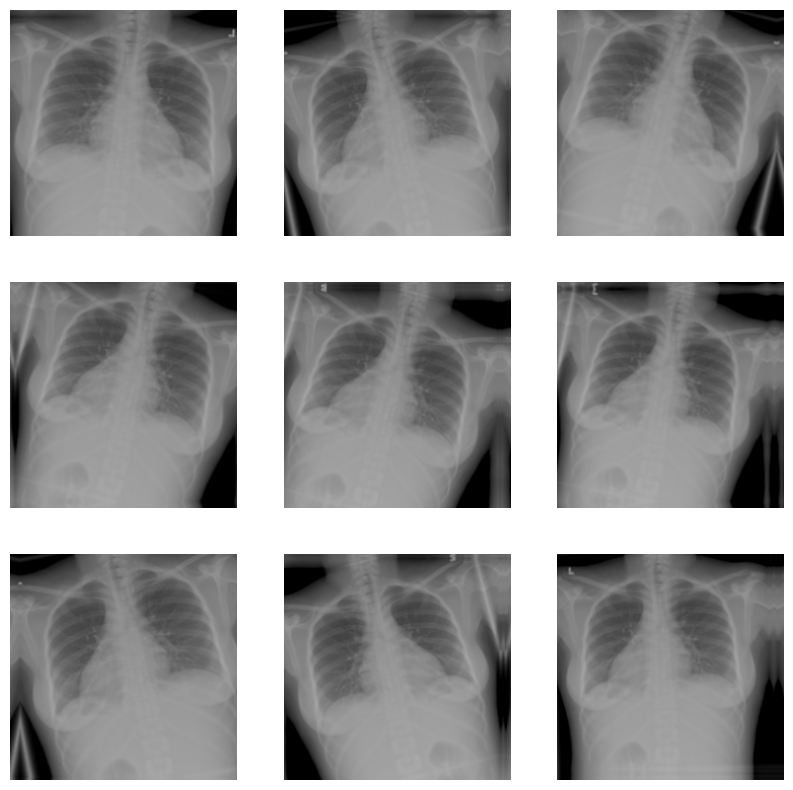

In [20]:
import matplotlib.pyplot as plt

for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [ ]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    
    layers.Lambda(preprocess_input),
    
    base_model,
    
    layers.GlobalAveragePooling2D(),
   

    layers.Dense(
        256,
        activation='relu',
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    layers.Dense(4, activation='softmax')
])

In [11]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_224 (Functional) │ (None, 7, 7, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,360,580 (12.82 MB)

 Trainable params: 131,716 (514.52 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

Epoch 1/10


2026-05-09 15:32:37.497638: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 74s 175ms/step - accuracy: 0.7849 - loss: 0.9232 - val_accuracy: 0.9054 - val_loss: 0.3725
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 73s 180ms/step - accuracy: 0.8753 - loss: 0.4257 - val_accuracy: 0.9198 - val_loss: 0.2365
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 76s 185ms/step - accuracy: 0.9000 - loss: 0.3045 - val_accuracy: 0.9106 - val_loss: 0.2429
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 74s 182ms/step - accuracy: 0.9047 - loss: 0.2589 - val_accuracy: 0.9277 - val_loss: 0.1764
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 71s 174ms/step - accuracy: 0.9107 - loss: 0.2352 - val_accuracy: 0.9238 - val_loss: 0.1897
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 65s 159ms/step - accuracy: 0.9105 - loss: 0.2256 - val_accuracy: 0.9448 - val_loss: 0.1523
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 64s 157ms/step - accuracy: 0.9095 - loss: 0.2326 - val_accuracy: 0.9238 - val_loss: 0.1836
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 65s 158ms/step - accuracy: 0.9143 - loss: 0.2262 - val

In [16]:
# Save the model
model.save('CXC106.keras')
print("Model saved successfully!")

Model saved successfully!


In [19]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.8972 - loss: 0.2544
Test Loss: 0.2544071078300476
Test Accuracy: 89.72%


2026-05-09 17:12:13.862969: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


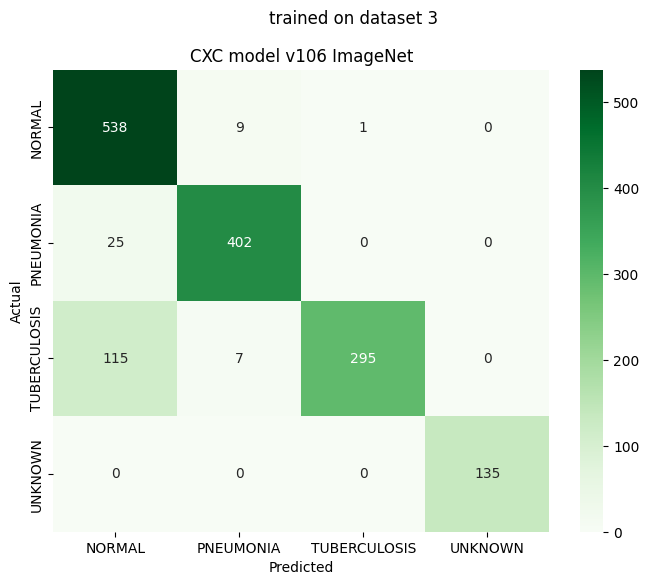

              precision    recall  f1-score   support

      NORMAL       0.79      0.98      0.88       548
   PNEUMONIA       0.96      0.94      0.95       427
TUBERCULOSIS       1.00      0.71      0.83       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.90      1527
   macro avg       0.94      0.91      0.91      1527
weighted avg       0.91      0.90      0.90      1527



In [ ]:
generate_confusion(test_ds, model=model, title="CXC 203 Confusion matrix on test dataset")

In [ ]:
generate_roc_curve(test_ds, model=model, title="CXC 203 ROC curve of test dataset")

In [ ]:
generate_confusion(val_ds, model=model, title="CXC 203 Confusion matrix on val dataset")

In [ ]:
generate_roc_curve(val_ds, model=model, title="CXC 203 ROC curve of val dataset")